In [ ]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import time
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score
import tensorflow as tf
from keras.layers import Input, Conv2D, BatchNormalization, MaxPooling2D, Flatten, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from keras import models, layers
from tensorflow.keras.callbacks import EarlyStopping

### Thêm lớp PCA

In [ ]:
class EigenfaceRecognizerPCA:
    def __init__(self, variance_threshold=0.95, img_size=(100, 100)):
        self.variance_threshold = variance_threshold
        self.img_size = img_size
        self.k_components = None
        self.mean_face = None
        self.eigenfaces = None
        self.projections = None
        self.y_train = None
        self.cumulative_variance_ratio = None
        self.n_total_components = None

    def fit(self, X_train, y_train):
        """Huấn luyện mô hình PCA (Eigenfaces)"""
        self.y_train = np.array(y_train)

        # 1. Tính khuôn mặt trung bình
        self.mean_face = np.mean(X_train, axis=0)
        A = X_train - self.mean_face

        # 2. Tính ma trận hiệp phương sai rút gọn L = A * A^T
        # Do trong numpy, vector là ma trận với 1 cột và nhiều hàng, nghĩa là A có kích thước (M, N^2)
        L = A @ A.T

        # 3. Tính trị riêng và vector riêng
        eigen_values, eigen_vectors = np.linalg.eigh(L)

        # 4. Sắp xếp theo thứ tự giảm dần
        idx = np.argsort(eigen_values)[::-1]
        eigen_values = eigen_values[idx]
        eigen_vectors = eigen_vectors[:, idx]

        self.n_total_components = len(eigen_values)

        # --- BỔ SUNG: TỰ ĐỘNG CHỌN K THEO CÔNG THỨC TRONG ẢNH ---
        # Tính tỷ lệ phương sai tích lũy r_k
        self.cumulative_variance_ratio = np.cumsum(eigen_values) / np.sum(eigen_values)

        # Tìm k nhỏ nhất sao cho r_k >= threshold
        self.k_components = np.argmax(self.cumulative_variance_ratio >= self.variance_threshold) + 1
        # -------------------------------------------------------

        # 5. Lấy K thành phần chính đã tính và tính Eigenfaces thật
        real_eigen_vectors = eigen_vectors[:, :self.k_components]
        self.eigenfaces = A.T @ real_eigen_vectors

        # Chuẩn hóa Eigenfaces
        self.eigenfaces /= np.linalg.norm(self.eigenfaces, axis=0)

        # 6. Chiếu dữ liệu huấn luyện vào không gian Eigenfaces
        self.projections = self.project(X_train)

        print(f"Ngưỡng phương sai: {self.variance_threshold * 100}%")
        print(f"Số lượng thành phần chính (K) được chọn: {self.k_components}")

    def plot_variance(self, dataset_name):
        """Vẽ biểu đồ phương sai tích lũy từ dữ liệu đã fit"""
        import matplotlib.pyplot as plt

        plt.figure(figsize=(10, 5))
        plt.plot(range(1, self.n_total_components + 1), self.cumulative_variance_ratio,
                 color='blue', lw=2, label='Phương sai tích lũy')

        plt.axhline(y=self.variance_threshold, color='red', linestyle='--',
                    label=f'Ngưỡng {self.variance_threshold*100:.0f}%')

        plt.axvline(x=self.k_components, color='green', linestyle='--',
                    label=f'k={self.k_components}')

        plt.title(f'Phân tích phương sai tích lũy - {dataset_name}')
        plt.xlabel('Số lượng thành phần chính (k)')
        plt.ylabel('Tỷ lệ phương sai giữ lại')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend(loc='lower right')
        plt.xlim(0, self.n_total_components)
        plt.ylim(0.3, 1.05)
        plt.show()

    def project(self, X):
        """
        Chiếu ảnh (hoặc danh sách ảnh) vào không gian Eigenfaces
        """
        return (X - self.mean_face) @ self.eigenfaces

    def find_optimal_threshold(self, X_val, y_val, steps=100):
        """
        Tìm ngưỡng tối ưu theta_f để phân biệt các khuôn mặt
        """
        val_projections = self.project(X_val)
        # Tính khoảng cách nhỏ nhất từ mỗi ảnh val đến tập train
        dists = np.linalg.norm(self.projections[None, :, :] - val_projections[:, None, :], axis=2)
        min_dists = np.min(dists, axis=1)
        pred_labels = self.y_train[np.argmin(dists, axis=1)]

        threshold_range = np.linspace(np.min(min_dists), np.max(min_dists), steps)

        best_theta = None
        min_dist_to_ideal = float('inf')
        results = []

        for theta in threshold_range:
            TP = np.sum((pred_labels == y_val) & (min_dists <= theta))
            FN = np.sum((pred_labels == y_val) & (min_dists > theta))
            FP = np.sum((pred_labels != y_val) & (min_dists <= theta))
            TN = np.sum((pred_labels != y_val) & (min_dists > theta))

            TPR = TP / (TP + FN) if (TP + FN) > 0 else 0
            FPR = FP / (FP + TN) if (FP + TN) > 0 else 0

            # Công thức (13): Khoảng cách đến điểm lý tưởng (0,1)
            dist_to_ideal = np.sqrt(FPR**2 + (1 - TPR)**2)

            if dist_to_ideal < min_dist_to_ideal:
                min_dist_to_ideal = dist_to_ideal
                best_theta = theta

            results.append((theta, FPR, TPR, dist_to_ideal))

        return best_theta, np.array(results)

    def plot_threshold_analysis(self, results, best_theta):
        """
        Hiển thị trực quan quá trình tìm ngưỡng tối ưu
        """
        thetas, fprs, tprs, dists = results[:, 0], results[:, 1], results[:, 2], results[:, 3]

        plt.figure(figsize=(15, 5))

        # Đồ thị 1: Mối quan hệ giữa Threshold và FPR/TPR
        plt.subplot(1, 2, 1)
        plt.plot(thetas, tprs, label='TPR (Đúng)', color='green', lw=2)
        plt.plot(thetas, fprs, label='FPR (Nhầm)', color='red', lw=2)
        plt.axvline(best_theta, color='blue', linestyle='--', label=f'Optimal θ: {best_theta:.0f}')
        plt.title("Phân tích TPR vs FPR theo Ngưỡng")
        plt.xlabel("Giá trị Ngưỡng (θ)")
        plt.ylabel("Tỷ lệ")
        plt.legend()
        plt.grid(True, alpha=0.3)

        # Đồ thị 2: Đường cong ROC và Điểm tối ưu theo công thức (13)
        plt.subplot(1, 2, 2)
        plt.plot(fprs, tprs, color='darkorange', lw=2, label='Đường cong ROC')
        plt.scatter(0, 1, color='green', marker='*', s=200, label='Điểm lý tưởng (0,1)')

        # Tìm tọa độ (FPR, TPR) của best_theta
        idx = np.argmin(np.abs(thetas - best_theta))
        plt.scatter(fprs[idx], tprs[idx], color='blue', s=100, label='Điểm tối ưu chọn được')

        plt.plot([0, fprs[idx]], [1, tprs[idx]], 'k--', alpha=0.5, label='Min Distance (Eq 13)')
        plt.title("Đường cong ROC & Điểm tối ưu θf")
        plt.xlabel("Tỷ lệ nhận nhầm (FPR)")
        plt.ylabel("Tỷ lệ nhận đúng (TPR)")
        plt.legend()
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    def predict(self, test_img, threshold=None):
        """
        Nhận diện và phát hiện người lạ dựa trên ngưỡng (threshold)
        """
        # Đảm bảo ảnh test có đúng kích thước và định dạng flatten
        test_proj = self.project(test_img)

        # Tính khoảng cách Euclide
        dists = np.linalg.norm(self.projections - test_proj, axis=1)
        min_idx = np.argmin(dists)
        d_min = dists[min_idx]
        identity = self.y_train[min_idx]

        if threshold and d_min > threshold:
            return "Unknown", d_min, identity

        return identity, d_min, identity

    def show_results(self, X_test, y_test, threshold=None, num_images=10):
        """Hàm hiển thị kết quả tự động thích ứng với kích thước ảnh của từng bộ dữ liệu"""
        indices = np.random.choice(len(X_test), num_images, replace=False)

        rows = (num_images + 1) // 2
        plt.figure(figsize=(12, rows * 4))

        for i, idx in enumerate(indices):
            test_img = X_test[idx]
            true_label = y_test[idx]

            pred_label, dist, _ = self.predict(test_img, threshold=threshold)

            plt.subplot(rows, 2, i + 1)

            plt.imshow(test_img.reshape(self.img_size), cmap='gray')

            if pred_label == "Unknown":
                color = 'orange'
            elif pred_label == true_label:
                color = 'green'
            else:
                color = 'red'

            plt.title(f"Thực tế: {true_label}\nDự đoán: {pred_label}\nd_min: {dist:.2f} | Ngưỡng: {threshold:.2f}",
                      color=color, fontsize=10, fontweight='bold')
            plt.axis('off')

        plt.tight_layout()
        plt.show()

    def show_eigenfaces_picture(self, num_people=5):
        """
        Hiển thị khuôn mặt tái tạo (Reconstructed Face) từ không gian Eigenfaces.
        Công thức: Face = Mean_Face + (Projection @ Eigenfaces^T)
        """
        unique_labels = np.unique(self.y_train)
        num_people = min(num_people, len(unique_labels)) # Tránh lỗi nếu num_people > số người thực tế

        cols = 3
        rows = (num_people + cols - 1) // cols

        plt.figure(figsize=(12, rows * 4))

        for i, label in enumerate(unique_labels[:num_people]):
            # 1. Tìm tất cả các vector chiếu (trọng số) của người này trong tập huấn luyện
            person_indices = np.where(self.y_train == label)[0]
            person_projections = self.projections[person_indices]

            # 2. Tính vector trọng số trung bình đại diện cho người đó (Mean Projection)
            mean_weight = np.mean(person_projections, axis=0)

            # 3. Tái tạo ảnh (Reconstruction) - Đã sửa lỗi thụt lề
            # Tương đương công thức: X_reconstructed = X_mean + W * U^T
            reconstructed_vector = self.mean_face + (mean_weight @ self.eigenfaces.T)
            reconstructed_face = reconstructed_vector.reshape(self.img_size)

            # 4. Hiển thị ảnh tái tạo
            plt.subplot(rows, cols, i + 1)
            plt.imshow(reconstructed_face, cmap='gray')
            plt.title(f"Đại diện: {label}")
            plt.axis('off')

        plt.suptitle(f"Khuôn mặt đại diện tái tạo từ {self.k_components} Eigenfaces", fontsize=15)
        plt.tight_layout()
        plt.show()

# Build mạng CNN

In [ ]:
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, MaxPooling2D, Flatten, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras import models, layers
import tensorflow as tf

def build_cnn(num_classes, img_shape):
    # img_shape sẽ là (height, width, 1)
    inputs = Input(shape=img_shape)

    # Tiền xử lý / Augmentation
    x = RandomFlip("horizontal")(inputs)
    x = RandomRotation(0.05)(x)
    x = RandomZoom(0.05)(x)

    # Khối 1: Trích xuất đặc trưng cơ bản
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    # Khối 2: Trích xuất đặc trưng chuyên sâu
    # Lớp tích chập l=2
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    # Lớp tích chập l=3
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    # Lớp tích chập l=4
    x = Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x)

    # Khối 3: Quyết định và phân loại
    x = Flatten()(x)
    x = Dense(512, activation='relu')(x) # Tăng lên 512 units để phù hợp với đặc trưng sâu
    x = Dropout(0.5)(x)

    # Đầu ra Softmax
    outputs = Dense(num_classes, activation='softmax')(x)

    # Khối 4: Tối ưu hóa
    model = models.Model(inputs=inputs, outputs=outputs)
    opt = tf.keras.optimizers.Adam(learning_rate=0.0005)
    model.compile(optimizer=opt,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

# Tải dữ liệu

In [ ]:
from sklearn.datasets import fetch_olivetti_faces, fetch_lfw_people

# --- BỘ DỮ LIỆU 1: TRUYỀN THỐNG (ORL) ---
print("Đang tải Bộ 1...")
orl = fetch_olivetti_faces()
X1, y1 = orl.data, orl.target # Ảnh xám, 64x64, chuẩn hóa sẵn

# --- BỘ DỮ LIỆU 2: PHI TUYẾN (LFW Subset - Nhiều ảnh/người) ---
print("Đang tải Bộ 2...")
# Lấy những người có nhiều góc cạnh, biểu cảm
min_faces_per_person_lfw_2 = 20
lfw_2 = fetch_lfw_people(min_faces_per_person=min_faces_per_person_lfw_2, resize=0.5)
X2, y2 = lfw_2.data, lfw_2.target

# --- BỘ DỮ LIỆU 3: QUY MÔ LỚN (LFW Full - Ảnh lớn) ---
print("Đang tải Bộ 3...")
# Lấy nhiều người hơn, ảnh giữ nguyên kích thước gốc để test CNN
min_faces_per_person_lfw_3= 40
lfw_3 = fetch_lfw_people(min_faces_per_person=min_faces_per_person_lfw_3, resize=1.0)
X3, y3 = lfw_3.data, lfw_3.target

print(f"\nKích thước hoàn tất:")
print(f"Bộ 1: {X1.shape} (Lý tưởng)")
print(f"Bộ 2: {X2.shape} (Phi tuyến - Ánh sáng/Góc chụp)")
print(f"Bộ 3: {X3.shape} (Phức tạp - Quy mô lớn)")

datasets = [
    ("Bộ 1 (ORL)", orl.data, orl.target, (64, 64)),
    ("Bộ 2 (LFW-P)", lfw_2.data, lfw_2.target, (62, 47)),
    ("Bộ 3 (LFW-G)", lfw_3.data, lfw_3.target, (100, 75))
]

Đang tải Bộ 1...
downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Đang tải Bộ 2...
Đang tải Bộ 3...

Kích thước hoàn tất:
Bộ 1: (400, 4096) (Lý tưởng)
Bộ 2: (3023, 2914) (Phi tuyến - Ánh sáng/Góc chụp)
Bộ 3: (1867, 11750) (Phức tạp - Quy mô lớn)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Hàm thêm ảnh bằng cách biến đổi
def balance_and_augment(X, y, target_samples=50):
    """
    Tự động cân bằng dữ liệu: Người nào ít ảnh hơn target_samples sẽ được tạo thêm.
    X: dữ liệu ảnh dạng vector phẳng hoặc 2D
    y: nhãn
    """
    # Reshape về dạng ảnh 2D để Augment (giả sử h, w đã có từ data_obj)
    # Ở đây dùng ImageDataGenerator để xoay/lật ảnh
    datagen = ImageDataGenerator(
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        shear_range=0.1,
        zoom_range=0.1,
        horizontal_flip=True,
        fill_mode='nearest'
    )

    new_X, new_y = [], []
    unique_classes = np.unique(y)

    for cls in unique_classes:
        cls_imgs = X[y == cls]
        n_samples = len(cls_imgs)

        # Giữ lại ảnh gốc
        for img in cls_imgs:
            new_X.append(img)
            new_y.append(cls)

        # Nếu thiếu ảnh, tạo thêm cho đủ target_samples
        if n_samples < target_samples:
            n_needed = target_samples - n_samples
            # Reshape tạm thời để qua datagen
            temp_imgs = cls_imgs.reshape(-1, h, w, 1)
            i = 0
            for batch in datagen.flow(temp_imgs, batch_size=1):
                new_X.append(batch[0].flatten())
                new_y.append(cls)
                i += 1
                if i >= n_needed: break

    return np.array(new_X), np.array(new_y)

In [ ]:
# Nhận diện ảnh lỗi
def is_suspicious(img):
    # Tự động nhận diện thang đo [0,1] hay [0,255]
    is_norm = np.max(img) <= 1.05

    mean_val = np.mean(img)
    std_val = np.std(img)

    # Ngưỡng an toàn thích ứng với thang đo
    m_low, m_high = (0.05, 0.95) if is_norm else (12, 243)
    s_min = 0.02 if is_norm else 5

    # Nếu ảnh quá tối, quá sáng hoặc quá phẳng (std thấp)
    if mean_val < m_low or mean_val > m_high or std_val < s_min:
        return True
    return False


PHÂN TÍCH NGƯỠNG PCA TỐI ƯU: Bộ 1 (ORL)
Ngưỡng phương sai: 95.0%
Số lượng thành phần chính (K) được chọn: 113

>>> Kết quả tính toán cho Bộ 1 (ORL):
- Ngưỡng tối ưu (Theta_f): 5.16


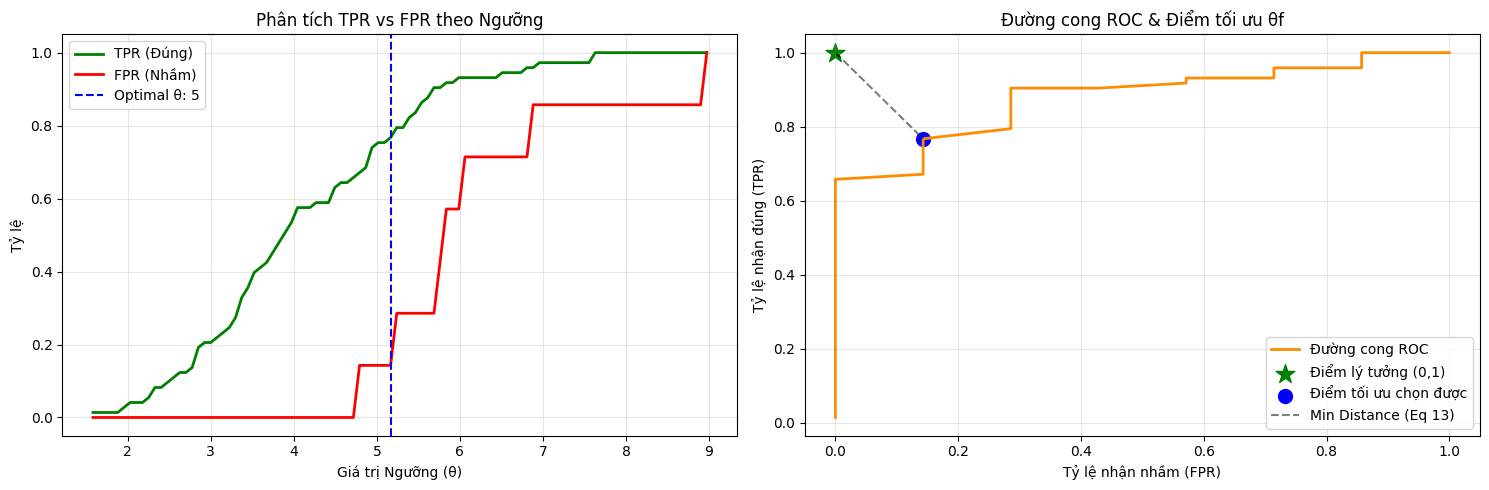

In [ ]:
name, X_data, y_data, img_shape = datasets[0]

print(f"\n" + "="*50)
print(f"PHÂN TÍCH NGƯỠNG PCA TỐI ƯU: {name}")
print("="*50)

# 1. Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42)

# 2. Huấn luyện PCA
model_pca = EigenfaceRecognizerPCA(variance_threshold=0.95, img_size=img_shape)
model_pca.fit(X_train, y_train)

# 3. Tìm ngưỡng tối ưu dựa trên công thức (13, 14, 15)
# Hàm này sẽ tính toán FPR, TPR và khoảng cách đến điểm lý tưởng (0,1)
best_theta_pca, res_pca = model_pca.find_optimal_threshold(X_test, y_test)

# 4. Hiển thị đồ thị phân tích
print(f"\n>>> Kết quả tính toán cho {name}:")
print(f"- Ngưỡng tối ưu (Theta_f): {best_theta_pca:.2f}")

model_pca.plot_threshold_analysis(res_pca, best_theta_pca)

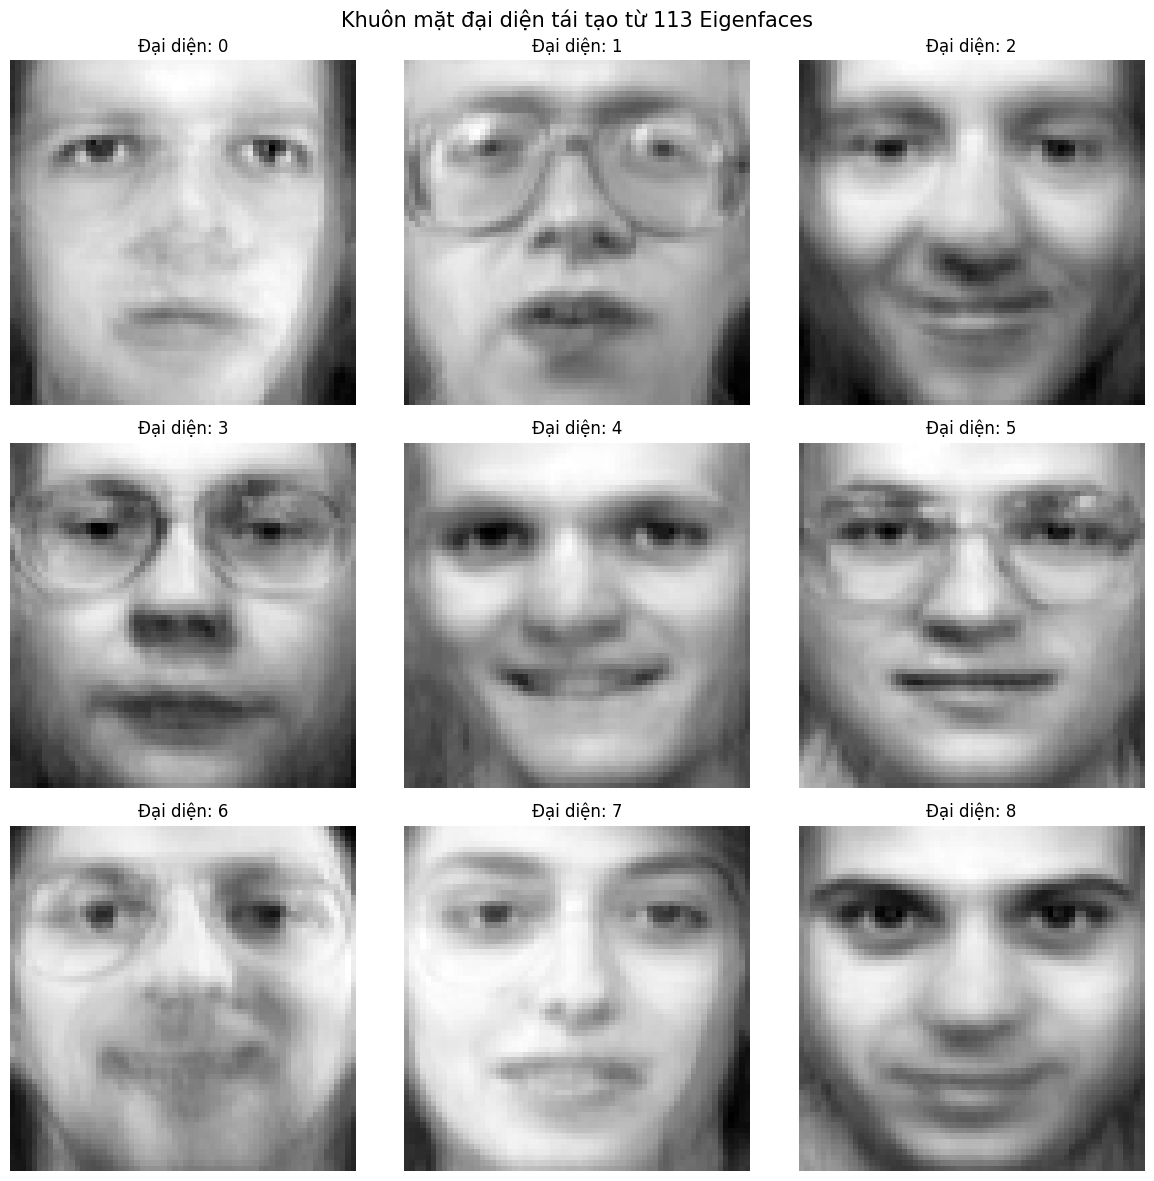

In [ ]:
model_pca.show_eigenfaces_picture(num_people=9)`

In [ ]:
# 1. Định nghĩa lại dữ liệu Bộ 1
name, X_data, y_data, img_shape = datasets[0]
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.2, random_state=42)

model_pca = EigenfaceRecognizerPCA(variance_threshold=0.95, img_size=img_shape)

# 3. Huấn luyện trên Bộ 1
model_pca.fit(X_train, y_train)

# 4. Tìm ngưỡng theta_c cho Bộ 1
best_theta_pca, res_pca = model_pca.find_optimal_threshold(X_test, y_test)

# 5. Xuất bảng khoảng cách
results_distance = []
indices = np.random.choice(len(X_test), 30, replace=False)

for i in indices:
    true_label = y_test[i]
    # Gọi hàm predict
    pred_label, d_min, _ = model_pca.predict(X_test[i], threshold=best_theta_pca)

    status = "Hợp lệ" if d_min <= best_theta_pca else "Từ chối"

    results_distance.append({
        'Ảnh mẫu': f"Test_{i}",
        'Danh tính thực': true_label,
        'd_min': f"{d_min:.2f}",
        'Ngưỡng theta_c': f"{best_theta_pca:.2f}",
        'Dự đoán': pred_label,
        'Trạng thái': status
    })

df_dist = pd.DataFrame(results_distance)
print(f"\nBẢNG PHÂN TÍCH KHOẢNG CÁCH EUCLIDEAN: {name}")
print("-" * 80)
print(df_dist.to_string(index=False))

Ngưỡng phương sai: 95.0%
Số lượng thành phần chính (K) được chọn: 113

BẢNG PHÂN TÍCH KHOẢNG CÁCH EUCLIDEAN: Bộ 1 (ORL)
--------------------------------------------------------------------------------
Ảnh mẫu  Danh tính thực d_min Ngưỡng theta_c Dự đoán Trạng thái
Test_34              23  4.78           5.16      23     Hợp lệ
Test_73               4  3.45           5.16       4     Hợp lệ
Test_39              14  2.41           5.16      14     Hợp lệ
Test_46              14  2.27           5.16      14     Hợp lệ
Test_23              27  4.81           5.16      27     Hợp lệ
Test_72               0  6.75           5.16 Unknown    Từ chối
Test_54              37  3.29           5.16      37     Hợp lệ
Test_17              37  3.17           5.16      37     Hợp lệ
Test_64              10  2.27           5.16      10     Hợp lệ
 Test_0              20  3.45           5.16      20     Hợp lệ
Test_66              35  4.70           5.16      35     Hợp lệ
Test_30              39  4.91  

--- KẾT QUẢ TRỰC QUAN TRÊN BỘ 1 (ORL) ---


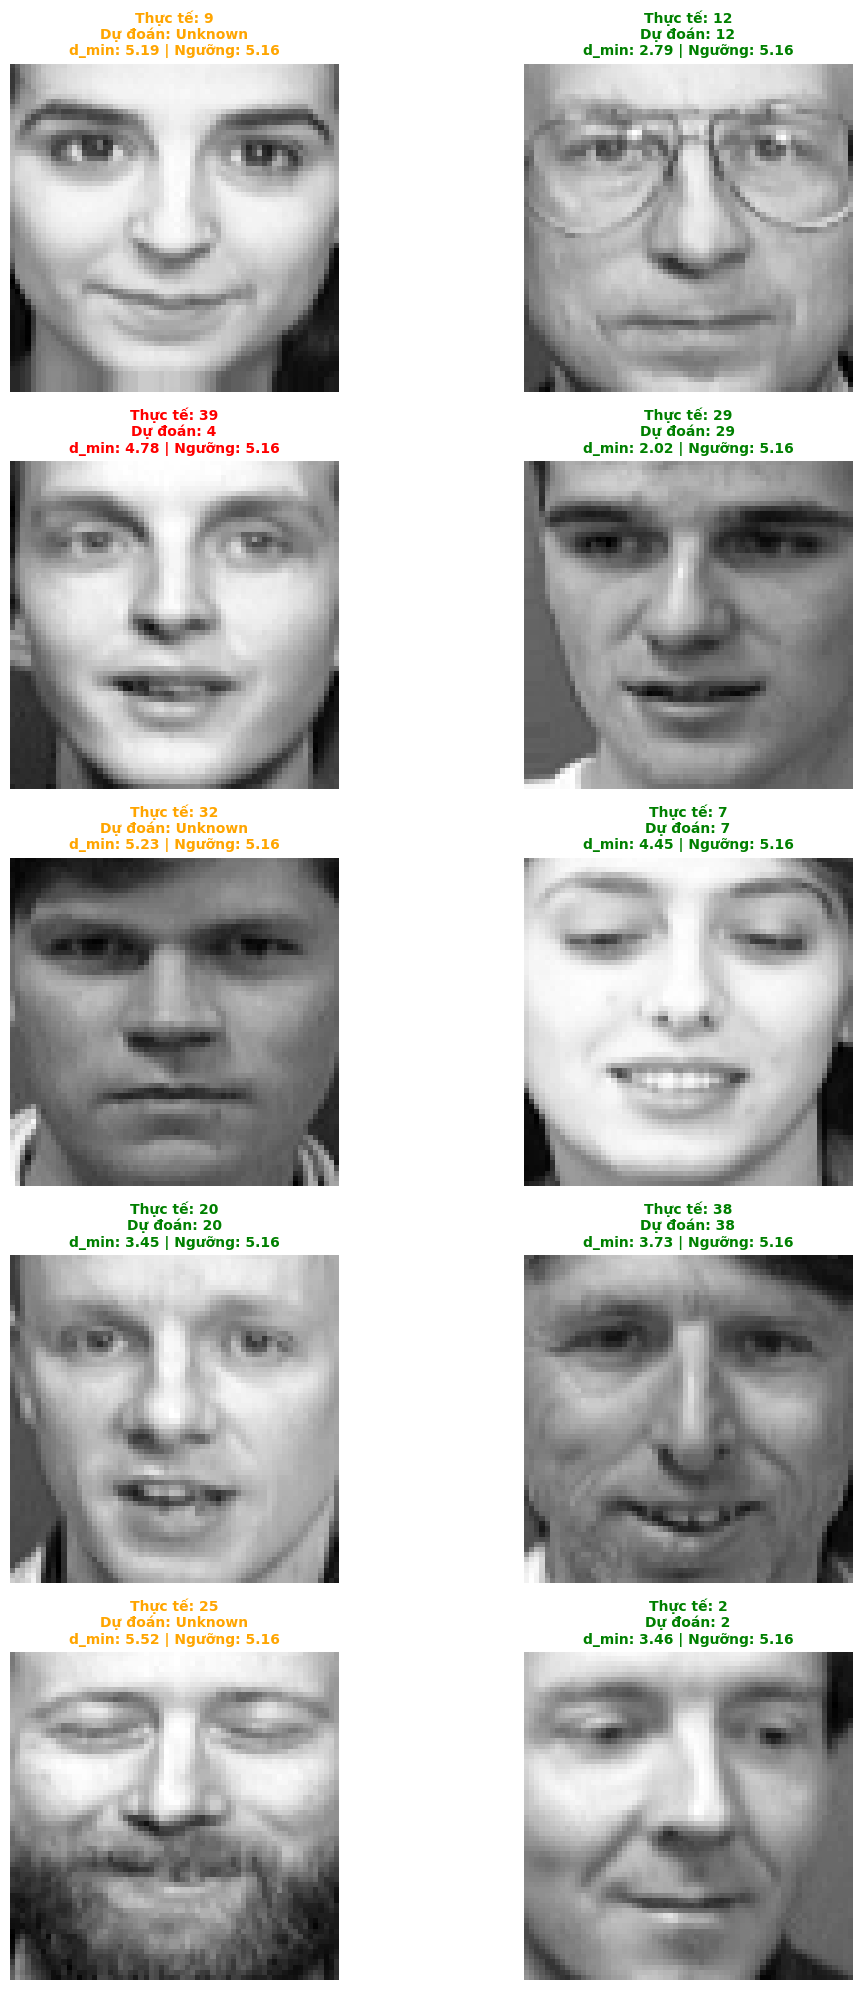

In [ ]:
print(f"--- KẾT QUẢ TRỰC QUAN TRÊN BỘ 1 (ORL) ---")

# Gọi hàm hiển thị
model_pca.show_results(X_test, y_test, threshold=best_theta_pca, num_images=10)


--- Đang thực nghiệm trên Bộ 1 (ORL) ---
Dataset gốc có: 400 với mỗi người có ít nhất 10 ảnh
Bộ dữ liệu ORL: Giữ nguyên 400 ảnh (Bỏ qua lọc lỗi).
Dataset sau khi được thêm có: 2000 ảnh, với mỗi người có ít nhất 50 ảnh
Bắt đầu chạy phương pháp PCA.

Ngưỡng phương sai: 95.0%
Số lượng thành phần chính (K) được chọn: 203


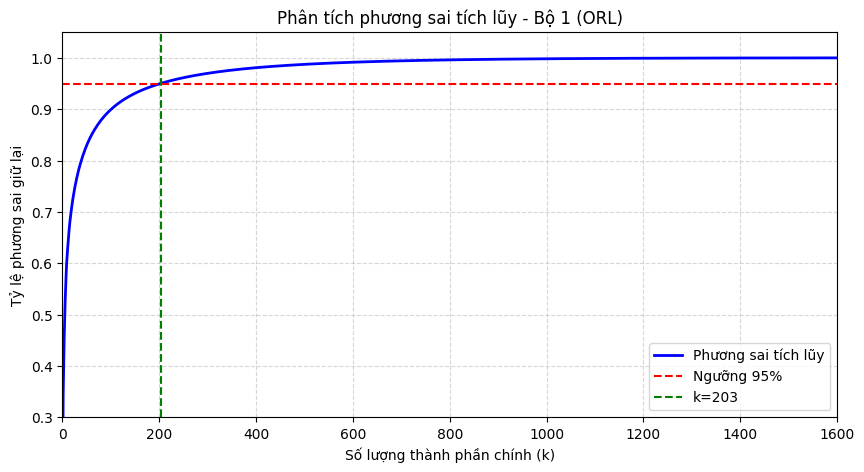

Đã chạy xong phương pháp PCA.

Bắt đầu chạy phương pháp PCA + SVM (Linear).

Đã chạy xong phương pháp PCA + SVM (Linear).

Bắt đầu chạy phương pháp PCA + SVM (RBF).

Đã chạy xong phương pháp PCA + SVM (RBF).

Bắt đầu chạy phương pháp CNN.

Epoch 98: early stopping
Restoring model weights from the end of the best epoch: 48.
Đã chạy xong phương pháp CNN.

Bắt đầu chạy phương pháp CNN + SVM.

Đã chạy xong phương pháp CNN + SVM.


--- Đang thực nghiệm trên Bộ 2 (LFW-P) ---
Dataset gốc có: 3023 với mỗi người có ít nhất 20 ảnh
Loại bỏ 0 ảnh lỗi/nghi ngờ.
Dataset sau khi được thêm có: 4060 ảnh, với mỗi người có ít nhất 50 ảnh
Bắt đầu chạy phương pháp PCA.

Ngưỡng phương sai: 95.0%
Số lượng thành phần chính (K) được chọn: 196


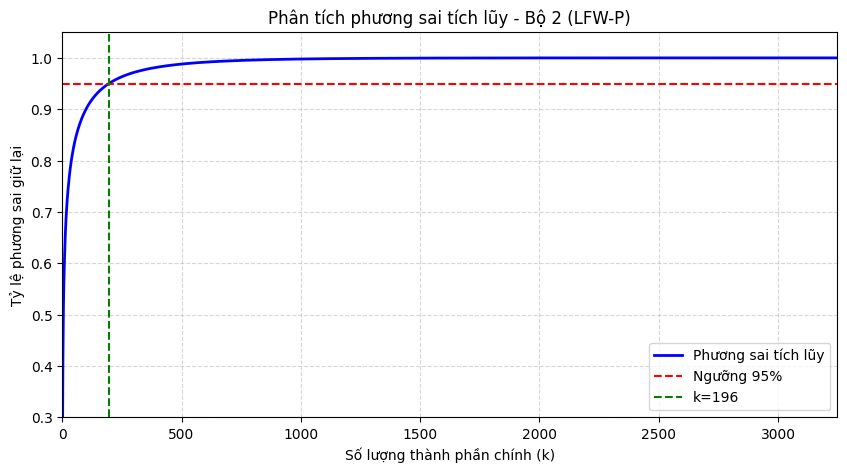

Đã chạy xong phương pháp PCA.

Bắt đầu chạy phương pháp PCA + SVM (Linear).

Đã chạy xong phương pháp PCA + SVM (Linear).

Bắt đầu chạy phương pháp PCA + SVM (RBF).

Đã chạy xong phương pháp PCA + SVM (RBF).

Bắt đầu chạy phương pháp CNN.

Epoch 87: early stopping
Restoring model weights from the end of the best epoch: 67.
Đã chạy xong phương pháp CNN.

Bắt đầu chạy phương pháp CNN + SVM.

Đã chạy xong phương pháp CNN + SVM.


--- Đang thực nghiệm trên Bộ 3 (LFW-G) ---
Dataset gốc có: 1867 với mỗi người có ít nhất 40 ảnh
Loại bỏ 0 ảnh lỗi/nghi ngờ.
Dataset sau khi được thêm có: 2540 ảnh, với mỗi người có ít nhất 100 ảnh
Bắt đầu chạy phương pháp PCA.

Ngưỡng phương sai: 95.0%
Số lượng thành phần chính (K) được chọn: 222


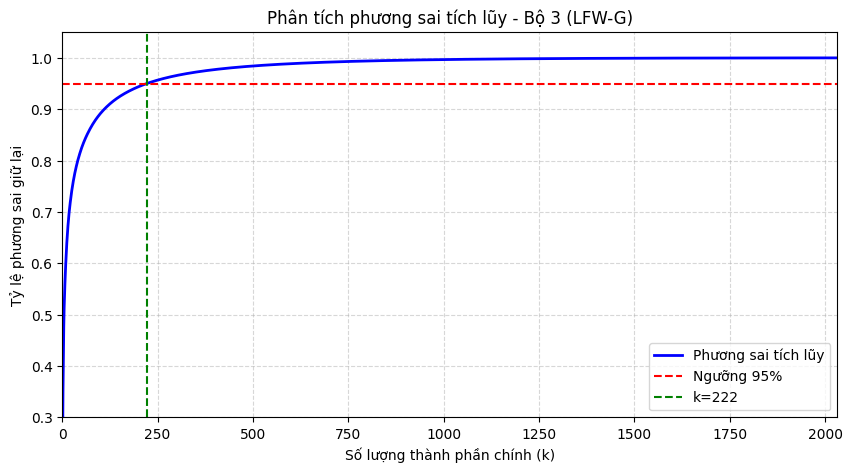

Đã chạy xong phương pháp PCA.

Bắt đầu chạy phương pháp PCA + SVM (Linear).

Đã chạy xong phương pháp PCA + SVM (Linear).

Bắt đầu chạy phương pháp PCA + SVM (RBF).

Đã chạy xong phương pháp PCA + SVM (RBF).

Bắt đầu chạy phương pháp CNN.

Epoch 84: early stopping
Restoring model weights from the end of the best epoch: 64.
Đã chạy xong phương pháp CNN.

Bắt đầu chạy phương pháp CNN + SVM.

Đã chạy xong phương pháp CNN + SVM.

Lưu kết quả thành công.


In [ ]:
from sklearn.metrics import precision_recall_fscore_support
# Tắt cảnh báo TensorFlow
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

final_report = []

datasets_config = [
    ("Bộ 1 (ORL)", orl),
    ("Bộ 2 (LFW-P)", lfw_2),
    ("Bộ 3 (LFW-G)", lfw_3)
]

for name, data_obj in datasets_config:
    print(f"\n--- Đang thực nghiệm trên {name} ---")

    X_raw = data_obj.data
    y_raw = data_obj.target
    real_shape = data_obj.images.shape[1:]
    h, w = real_shape

    if name == "Bộ 1 (ORL)":
        print(f'Dataset gốc có: {X_raw.shape[0]} với mỗi người có ít nhất 10 ảnh')
    elif name == "Bộ 2 (LFW-P)":
        print(f'Dataset gốc có: {X_raw.shape[0]} với mỗi người có ít nhất {min_faces_per_person_lfw_2} ảnh')
    else:
        print(f'Dataset gốc có: {X_raw.shape[0]} với mỗi người có ít nhất {min_faces_per_person_lfw_3} ảnh')

    if "ORL" in name:
        X_cleaned = X_raw
        y_cleaned = y_raw
        print(f"Bộ dữ liệu ORL: Giữ nguyên {len(X_cleaned)} ảnh (Bỏ qua lọc lỗi).")
    else:
        valid_indices = [i for i, img in enumerate(X_raw) if not is_suspicious(img)]
        X_cleaned = X_raw[valid_indices]
        y_cleaned = y_raw[valid_indices]
        print(f"Loại bỏ {len(X_raw) - len(X_cleaned)} ảnh lỗi/nghi ngờ.")
    # Thêm ảnh
    if name == "Bộ 3 (LFW-G)": # vì bộ 3 có ít nhất 30 mẫu cho mỗi người (class) rồi
        current_target = 100
    else:
        current_target = 50

    X, y = balance_and_augment(X_cleaned, y_cleaned, target_samples=current_target)
    print(f"Dataset sau khi được thêm có: {X.shape[0]} ảnh, với mỗi người có ít nhất {current_target} ảnh")

    num_samples = X.shape[0]           # Số lượng ảnh
    num_classes = len(np.unique(y))    # Số lượng người
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Chuẩn bị nhãn cho CNN và các chỉ số (LabelEncoder)
    le = LabelEncoder()
    y_train_enc = le.fit_transform(y_train)
    y_test_enc = le.transform(y_test)
    num_classes = len(le.classes_)

    # ---------------------------------------------------------
    # 1. CHẠY PCA (Euclidean)
    # ---------------------------------------------------------
    print('Bắt đầu chạy phương pháp PCA.\n')
    model_pca = EigenfaceRecognizerPCA(variance_threshold=0.95, img_size=real_shape)
    train_start = time.time()
    model_pca.fit(X_train, y_train)

    model_pca.plot_variance(name)

    t_train_pca = time.time() - train_start

    test_start = time.time()
    y_pred_pca = [model_pca.predict(img)[0] for img in X_test]
    t_inf_pca = (time.time() - test_start) / len(X_test)

    acc_pca = accuracy_score(y_test, y_pred_pca)
    # Tính Recall và F1 (average='weighted' để phù hợp với phân loại đa lớp)
    prec_pca, rec_pca, f1_pca, _ = precision_recall_fscore_support(y_test, y_pred_pca, average='weighted', zero_division=0)
    print('Đã chạy xong phương pháp PCA.\n')

    # ---------------------------------------------------------
    # 2. CHẠY PCA + SVM (Linear)
    # ---------------------------------------------------------
    print('Bắt đầu chạy phương pháp PCA + SVM (Linear).\n')
    svm_clf_1 = SVC(kernel='linear')
    train_start = time.time()
    svm_clf_1.fit(model_pca.projections, y_train)
    t_train_svm_linear = (time.time() - train_start) + t_train_pca # SVM cần cả thời gian PCA fit

    test_start = time.time()
    X_test_pca = model_pca.project(X_test)
    y_pred_svm_linear = svm_clf_1.predict(X_test_pca)
    t_inf_svm_linear = (time.time() - test_start) / len(X_test)

    acc_svm_linear = accuracy_score(y_test, y_pred_svm_linear)
    prec_svm_linear, rec_svm_linear, f1_svm_linear, _ = precision_recall_fscore_support(y_test, y_pred_svm_linear, average='weighted', zero_division=0)

    print('Đã chạy xong phương pháp PCA + SVM (Linear).\n')
    # ---------------------------------------------------------
    # 2. CHẠY PCA + SVM (RBF)
    # ---------------------------------------------------------
    print('Bắt đầu chạy phương pháp PCA + SVM (RBF).\n')
    svm_clf_2 = SVC(kernel='rbf')
    train_start = time.time()
    svm_clf_2.fit(model_pca.projections, y_train)
    t_train_svm_rbf = (time.time() - train_start) + t_train_pca # SVM cần cả thời gian PCA fit

    test_start = time.time()
    X_test_pca = model_pca.project(X_test)
    y_pred_svm_rbf = svm_clf_2.predict(X_test_pca)
    t_inf_svm_rbf = (time.time() - test_start) / len(X_test)

    acc_svm_rbf = accuracy_score(y_test, y_pred_svm_rbf)
    prec_svm_rbf, rec_svm_rbf, f1_svm_rbf, _ = precision_recall_fscore_support(y_test, y_pred_svm_rbf, average='weighted', zero_division=0)
    print('Đã chạy xong phương pháp PCA + SVM (RBF).\n')

    # ---------------------------------------------------------
    # 3. CHẠY CNN
    # ---------------------------------------------------------
    print('Bắt đầu chạy phương pháp CNN.\n')
    X_train_cnn = X_train.reshape(-1, h, w, 1)
    X_test_cnn = X_test.reshape(-1, h, w, 1)

    patience_value = 50 if name == "Bộ 1 (ORL)" else 20

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=patience_value,
        restore_best_weights=True,
        verbose=1
    )
    cnn_model = build_cnn(num_classes=num_classes, img_shape=(h, w, 1))

    train_start = time.time()

    history = cnn_model.fit(
            X_train_cnn, y_train,
            epochs=150,
            batch_size=64,
            validation_split=0.2,
            callbacks=[early_stop],
            verbose=0
    )

    t_train_cnn = time.time() - train_start

    test_start = time.time()
    y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn, verbose=0), axis=1)
    t_inf_cnn = (time.time() - test_start) / len(X_test)

    acc_cnn = accuracy_score(y_test_enc, y_pred_cnn)
    prec_cnn, rec_cnn, f1_cnn, _ = precision_recall_fscore_support(y_test_enc, y_pred_cnn, average='weighted', zero_division=0)
    print('Đã chạy xong phương pháp CNN.\n')

    # ---------------------------------------------------------
    # 4. CHẠY HYBRID (CNN + SVM)
    # ---------------------------------------------------------
    print('Bắt đầu chạy phương pháp CNN + SVM.\n')
    # Bước 1: Trích xuất đặc trưng (Features) từ lớp sát cuối của CNN
    feature_extractor = models.Model(inputs=cnn_model.input,
                                 outputs=cnn_model.layers[-2].output)

    X_train_features = feature_extractor.predict(X_train_cnn, verbose=0)
    X_test_features = feature_extractor.predict(X_test_cnn, verbose=0)

    # Bước 2: Huấn luyện SVM trên các đặc trưng vừa trích xuất
    svm_hybrid = SVC(kernel='linear', probability=True)
    train_start = time.time()
    svm_hybrid.fit(X_train_features, y_train_enc)
    t_train_hybrid = time.time() - train_start + t_train_cnn # Thời gian train CNN + SVM ( cộng thêm thời gian huấn luyện ở phần CNN)

    # Bước 3: Dự đoán và đo thời gian suy luận
    test_start = time.time()
    y_pred_hybrid = svm_hybrid.predict(X_test_features)
    t_inf_hybrid = (time.time() - test_start) / len(X_test_cnn)

    # Bước 4: Tính toán các chỉ số Accuracy, Recall, F1-score
    acc_hybrid = accuracy_score(y_test_enc, y_pred_hybrid)
    prec_hybrid, rec_hybrid, f1_hybrid, _ = precision_recall_fscore_support(
        y_test_enc, y_pred_hybrid, average='weighted', zero_division=0
    )
    print('Đã chạy xong phương pháp CNN + SVM.\n')

    # ---------------------------------------------------------
    # LƯU KẾT QUẢ VÀO DANH SÁCH
    # ---------------------------------------------------------

    methods = [
        ("PCA", acc_pca, rec_pca, f1_pca, t_train_pca, t_inf_pca),
        ("PCA+SVM (Linear)", acc_svm_linear, rec_svm_linear, f1_svm_linear, t_train_svm_linear, t_inf_svm_linear),
        ("PCA+SVM (RBF)", acc_svm_rbf, rec_svm_rbf, f1_svm_rbf, t_train_svm_rbf, t_inf_svm_rbf),
        ("CNN", acc_cnn, rec_cnn, f1_cnn, t_train_cnn, t_inf_cnn),
        ("CNN + SVM", acc_hybrid, rec_hybrid, f1_hybrid, t_train_hybrid, t_inf_hybrid)
    ]

    for m_name, acc, rec, f1, t_train, t_inf in methods:
        final_report.append({
            'Dataset': name,
            'Samples': num_samples,
            'Classes': num_classes,
            'Method': m_name,
            'Accuracy': f"{acc*100:.2f}%",
            'Recall': f"{rec:.4f}",
            'F1-Score': f"{f1:.4f}",
            'Train Time (s)': f"{t_train:.4f}",
            'Inf Time (s)': f"{t_inf:.6f}"
        })
print('Lưu kết quả thành công.')


Tài liệu tham khảo
1. Turk, M., & Pentland, A. (1991). Eigenfaces for recognition. Journal of Cognitive Neuroscience.


In [ ]:
# Xuất bảng kết quả
df_report = pd.DataFrame(final_report)
print("\nKẾT QUẢ TỔNG HỢP CHI TIẾT:")
print("="*120)
# pivot để dễ quan sát hoặc in trực tiếp
print(df_report.to_string(index=False))
print("="*120)


KẾT QUẢ TỔNG HỢP CHI TIẾT:
     Dataset  Samples  Classes           Method Accuracy Recall F1-Score Train Time (s) Inf Time (s)
  Bộ 1 (ORL)     2000       40              PCA   76.75% 0.7675   0.7718         1.3142     0.000838
  Bộ 1 (ORL)     2000       40 PCA+SVM (Linear)   84.00% 0.8400   0.8415         1.6115     0.000295
  Bộ 1 (ORL)     2000       40    PCA+SVM (RBF)   87.00% 0.8700   0.8724         2.0028     0.001031
  Bộ 1 (ORL)     2000       40              CNN   99.25% 0.9925   0.9924        68.6215     0.001941
  Bộ 1 (ORL)     2000       40        CNN + SVM  100.00% 1.0000   1.0000        69.4655     0.000217
Bộ 2 (LFW-P)     4060       62              PCA   33.50% 0.3350   0.3371         6.9027     0.001318
Bộ 2 (LFW-P)     4060       62 PCA+SVM (Linear)   51.60% 0.5160   0.5091         9.0278     0.000782
Bộ 2 (LFW-P)     4060       62    PCA+SVM (RBF)   39.04% 0.3904   0.3408         9.1755     0.001132
Bộ 2 (LFW-P)     4060       62              CNN   85.22% 0.8522

In [ ]:
import pandas as pd

# Giả định df_report đã được tạo từ final_report của bạn
df_report = pd.DataFrame(final_report)

print("\n" + "="*50)
print("PHÂN TÍCH KẾT QUẢ THEO TỪNG BỘ DỮ LIỆU")
print("="*50)

# Lấy danh sách các bộ dữ liệu duy nhất (Bộ 1, Bộ 2, Bộ 3)
datasets = df_report['Dataset'].unique()

for ds in datasets:
    # Lọc dữ liệu cho từng bộ
    df_subset = df_report[df_report['Dataset'] == ds].copy()

    # In tên bộ dữ liệu làm tiêu đề bảng
    print(f"\n>>> {ds.upper()}:")
    print("-" * 110)

    # Bỏ cột 'Dataset' khi in vì tiêu đề đã ghi rồi, giúp bảng gọn hơn
    # index=False để không hiện số thứ tự dòng
    print(df_subset.drop(columns=['Dataset']).to_string(index=False))

    # Tính toán nhanh dòng tốt nhất (tùy chọn)
    best_acc = df_subset['Accuracy'].max()
    print("-" * 110)
    print(f"Nhận xét nhanh: Độ chính xác cao nhất của {ds} đạt {best_acc}")
    print("=" * 110)


PHÂN TÍCH KẾT QUẢ THEO TỪNG BỘ DỮ LIỆU

>>> BỘ 1 (ORL):
--------------------------------------------------------------------------------------------------------------
 Samples  Classes           Method Accuracy Recall F1-Score Train Time (s) Inf Time (s)
    2000       40              PCA   76.75% 0.7675   0.7718         1.3142     0.000838
    2000       40 PCA+SVM (Linear)   84.00% 0.8400   0.8415         1.6115     0.000295
    2000       40    PCA+SVM (RBF)   87.00% 0.8700   0.8724         2.0028     0.001031
    2000       40              CNN   99.25% 0.9925   0.9924        68.6215     0.001941
    2000       40        CNN + SVM  100.00% 1.0000   1.0000        69.4655     0.000217
--------------------------------------------------------------------------------------------------------------
Nhận xét nhanh: Độ chính xác cao nhất của Bộ 1 (ORL) đạt 99.25%

>>> BỘ 2 (LFW-P):
--------------------------------------------------------------------------------------------------------------

In [ ]:
# Chuyển đổi dữ liệu từ bảng final_report sang số float
df_plot = df_report.copy()
df_plot['Accuracy_Val'] = df_plot['Accuracy'].str.replace('%', '').astype(float)
df_plot['Train_Time_Val'] = df_plot['Train Time (s)'].astype(float)
# Đổi Inf Time sang miligiây (ms) để biểu đồ dễ nhìn hơn vì nó rất nhỏ
df_plot['Inf_Time_ms'] = df_plot['Inf Time (s)'].astype(float) * 1000

sns.set_style("whitegrid")

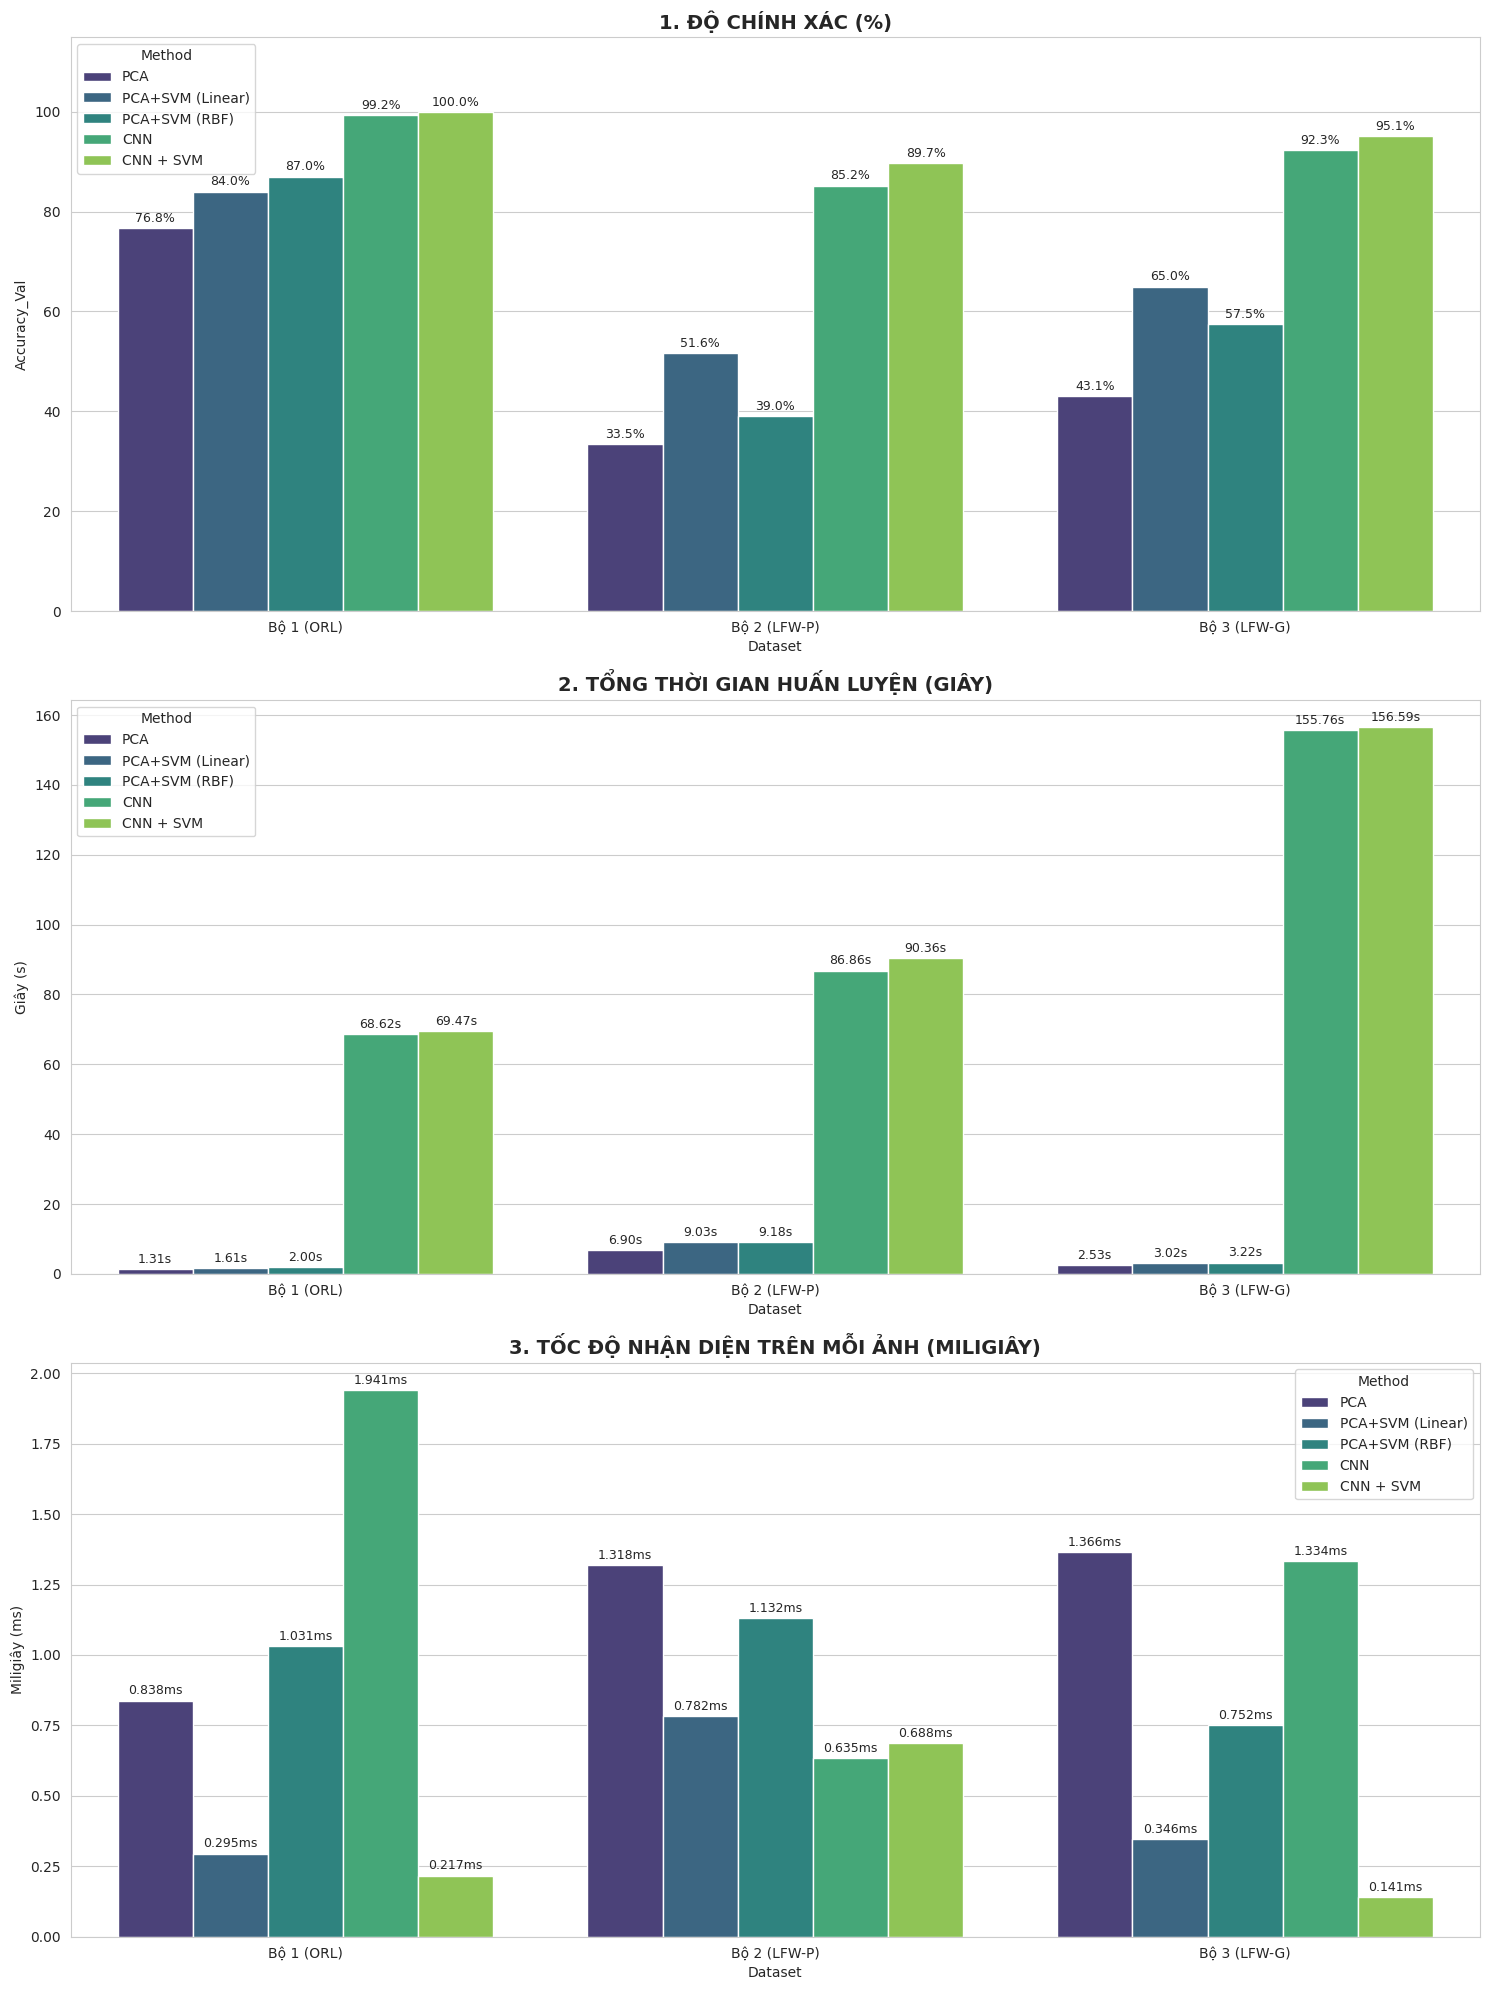

In [ ]:
# Tạo khung gồm 3 hàng để vẽ 3 biểu đồ
fig, axes = plt.subplots(3, 1, figsize=(15, 20))

# --- BIỂU ĐỒ 1: ACCURACY ---
ax1 = sns.barplot(x='Dataset', y='Accuracy_Val', hue='Method', data=df_plot, ax=axes[0], palette='viridis')
axes[0].set_title('1. ĐỘ CHÍNH XÁC (%)', fontsize=14, fontweight='bold')
axes[0].set_ylim(0, 115)
for p in ax1.patches:
    if p.get_height() > 0:
        ax1.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 7), textcoords='offset points', fontsize=9)

# --- BIỂU ĐỒ 2: TRAIN TIME ---
ax2 = sns.barplot(x='Dataset', y='Train_Time_Val', hue='Method', data=df_plot, ax=axes[1], palette='viridis')
axes[1].set_title('2. TỔNG THỜI GIAN HUẤN LUYỆN (GIÂY)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Giây (s)')
for p in ax2.patches:
    if p.get_height() > 0:
        ax2.annotate(f'{p.get_height():.2f}s', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 7), textcoords='offset points', fontsize=9)

# --- BIỂU ĐỒ 3: INF TIME (Tốc độ nhận diện mỗi ảnh) ---
ax3 = sns.barplot(x='Dataset', y='Inf_Time_ms', hue='Method', data=df_plot, ax=axes[2], palette='viridis')
axes[2].set_title('3. TỐC ĐỘ NHẬN DIỆN TRÊN MỖI ẢNH (MILIGIÂY)', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Miligiây (ms)')
for p in ax3.patches:
    if p.get_height() > 0:
        ax3.annotate(f'{p.get_height():.3f}ms', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 7), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

### Tài liệu tham khảo:
1. Matthew Turk và Alex Pentland, "Eigenfaces for Recognition" in Journal of Cognitive Neuroscience (1991)
2. Peter N. Belhumeur, Joao~ P. Hespanha, and David J. Kriegman, "Eigenfaces vs. Fisherfaces: Recognition
Using Class Specific Linear Projection" in IEEE transactions on pattern analysis and machine intelligence, 1997, pp. 718